In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving hotel_bookings.xls to hotel_bookings.xls


In [2]:
df = pd.read_csv("hotel_bookings.xls")

# Preserve the original data.
raw_df = df.copy()

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 119390
Columns: 32
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int6

In [4]:
missing = df.isna().sum()
print(missing[missing > 0])

children         4
country        488
agent        16340
company     112593
dtype: int64


In [5]:
print("Identical rows:", df.duplicated().sum())

display(df.describe())

print("Hotel types:")
print(df["hotel"].value_counts())

print("\nReservation status:")
print(df["reservation_status"].value_counts())

print("\nRoom-rate range:")
print(df["adr"].min(), "to", df["adr"].max())

Identical rows: 31994


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


Hotel types:
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

Reservation status:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

Room-rate range:
-6.38 to 5400.0


In [6]:
# Remove extra spaces from text columns.
text_cols = df.select_dtypes(include=["object"]).columns

for col in text_cols:
    df[col] = df[col].str.strip()

# Keep a flag identifying originally missing guest origins.
df["country_missing"] = df["country"].isna().astype(int)
df["country"] = df["country"].fillna("Unknown")

# Use the most common children count for the 4 missing values.
df["children_missing"] = df["children"].isna().astype(int)
df["children"] = df["children"].fillna(df["children"].mode()[0])

# Treat agent/company numbers as identifiers, not measurements.
# Preserve missing values because their meaning is not confirmed.
for col in ["agent", "company"]:
    df[col] = df[col].astype("Int64").astype("string")

print(df.isna().sum()[lambda s: s > 0])

agent       16340
company    112593
dtype: int64


In [7]:
df["identical_record_flag"] = (
    raw_df.duplicated(keep=False).astype(int)
)

print("Repeated rows beyond the first occurrence:",
      raw_df.duplicated().sum())

Repeated rows beyond the first occurrence: 31994


In [9]:
month_map = {
    "January": 1, "February": 2, "March": 3,
    "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9,
    "October": 10, "November": 11, "December": 12
}

df["arrival_month_number"] = df["arrival_date_month"].map(month_map)

df["arrival_date"] = pd.to_datetime(
    {
        "year": df["arrival_date_year"],
        "month": df["arrival_month_number"],
        "day": df["arrival_date_day_of_month"]
    },
    errors="coerce"
)

df["total_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)

# Derived dates, rather than separately observed dates.
df["estimated_booking_date"] = (
    df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
)

df["scheduled_checkout_date"] = (
    df["arrival_date"] + pd.to_timedelta(df["total_nights"], unit="D")
)

df["invalid_date_flag"] = (
    df["arrival_date"].isna()
    | df["lead_time"].lt(0)
    | df["stays_in_weekend_nights"].lt(0)
    | df["stays_in_week_nights"].lt(0)
).astype(int)

print("Invalid date/stay records:", df["invalid_date_flag"].sum())
print("Zero-night records:", df["total_nights"].eq(0).sum())

Invalid date/stay records: 0
Zero-night records: 715


In [11]:
month_map = {
    "January": 1, "February": 2, "March": 3,
    "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9,
    "October": 10, "November": 11, "December": 12
}

df["arrival_month_number"] = df["arrival_date_month"].map(month_map)

df["arrival_date"] = pd.to_datetime(
    {
        "year": df["arrival_date_year"],
        "month": df["arrival_month_number"],
        "day": df["arrival_date_day_of_month"]
    },
    errors="coerce"
)

df["total_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)

# Derived dates, rather than separately observed dates.
df["estimated_booking_date"] = (
    df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
)

df["scheduled_checkout_date"] = (
    df["arrival_date"] + pd.to_timedelta(df["total_nights"], unit="D")
)

df["invalid_date_flag"] = (
    df["arrival_date"].isna()
    | df["lead_time"].lt(0)
    | df["stays_in_weekend_nights"].lt(0)
    | df["stays_in_week_nights"].lt(0)
).astype(int)

print("Invalid date/stay records:", df["invalid_date_flag"].sum())
print("Zero-night records:", df["total_nights"].eq(0).sum())

Invalid date/stay records: 0
Zero-night records: 715


In [12]:
print("Negative rates:", df["adr"].lt(0).sum())
print("Zero rates:", df["adr"].eq(0).sum())

display(df.nlargest(5, "adr")[
    ["hotel", "reserved_room_type", "adr", "total_nights"]
])

df["negative_rate_flag"] = df["adr"].lt(0).astype(int)

# Negative room rates are unsuitable for rate analysis.
# Preserve the original adr column.
df["adr_clean"] = df["adr"].mask(df["adr"].lt(0))

# Flag unusually high rates within each hotel and room category.
groups = df.groupby(["hotel", "reserved_room_type"])["adr_clean"]

q1 = groups.transform(lambda s: s.quantile(0.25))
q3 = groups.transform(lambda s: s.quantile(0.75))

df["high_rate_flag"] = (
    df["adr_clean"] > q3 + 1.5 * (q3 - q1)
).astype(int)

print("High-rate flags:", df["high_rate_flag"].sum())

Negative rates: 1
Zero rates: 1959


,hotel,reserved_room_type,adr,total_nights
48515,City Hotel,A,5400.0,1
111403,City Hotel,A,510.0,1
15083,Resort Hotel,A,508.0,1
103912,City Hotel,E,451.5,2
13142,Resort Hotel,A,450.0,14


High-rate flags: 2801


In [13]:
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, np.inf],
    labels=["0–7", "8–30", "31–90", "91–180", "181+"]
)

df["total_guests"] = df["adults"] + df["children"] + df["babies"]

df["repeat_guest_label"] = df["is_repeated_guest"].map({
    0: "First-time guest",
    1: "Repeat guest"
})

df["arrival_day"] = df["arrival_date"].dt.day_name()

df["weekend_arrival"] = (
    df["arrival_date"].dt.dayofweek >= 5
).astype(int)

# Explicit Northern Hemisphere meteorological-season definition.
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

df["season"] = df["arrival_month_number"].map(season_map)

df["completed_stay"] = (
    df["reservation_status"] == "Check-Out"
).astype(int)

df["completed_stay_nights"] = np.where(
    df["completed_stay"].eq(1),
    df["total_nights"],
    0
)

display(df[
    ["arrival_date", "total_nights", "lead_time_group",
     "total_guests", "repeat_guest_label", "season",
     "completed_stay_nights"]
].head())

,arrival_date,total_nights,lead_time_group,total_guests,repeat_guest_label,season,completed_stay_nights
0,2015-07-01,0,181+,2.0,First-time guest,Summer,0
1,2015-07-01,0,181+,2.0,First-time guest,Summer,0
2,2015-07-01,1,0–7,1.0,First-time guest,Summer,1
3,2015-07-01,1,8–30,1.0,First-time guest,Summer,1
4,2015-07-01,2,8–30,2.0,First-time guest,Summer,2


In [15]:
# Keep invalid records separately for documentation.
invalid_records = df[df["invalid_date_flag"].eq(1)].copy()

clean_df = df[df["invalid_date_flag"].eq(0)].copy()

print("Original rows:", len(raw_df))
print("Prepared rows:", len(clean_df))
print("Excluded invalid date/stay rows:", len(invalid_records))

clean_df.to_csv("cleaned_hotel_bookings.csv", index=False)

from google.colab import files
files.download("cleaned_hotel_bookings.csv")

Original rows: 119390
Prepared rows: 119390
Excluded invalid date/stay rows: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
print("Total bookings:", len(clean_df))
print("Cancelled bookings:", clean_df["is_canceled"].sum())
print(
    "Cancellation rate:",
    round(clean_df["is_canceled"].mean() * 100, 2), "%"
)
print("Completed stays:", clean_df["completed_stay"].sum())
print("Average lead time:",
      round(clean_df["lead_time"].mean(), 1), "days")

Total bookings: 119390
Cancelled bookings: 44224
Cancellation rate: 37.04 %
Completed stays: 75166
Average lead time: 104.0 days


,distribution_channel,total_bookings,cancelled_bookings,cancellation_rate
4,Undefined,5,4,80.00
3,TA/TO,97870,40152,41.03
0,Corporate,6677,1474,22.08
2,GDS,193,37,19.17
1,Direct,14645,2557,17.46


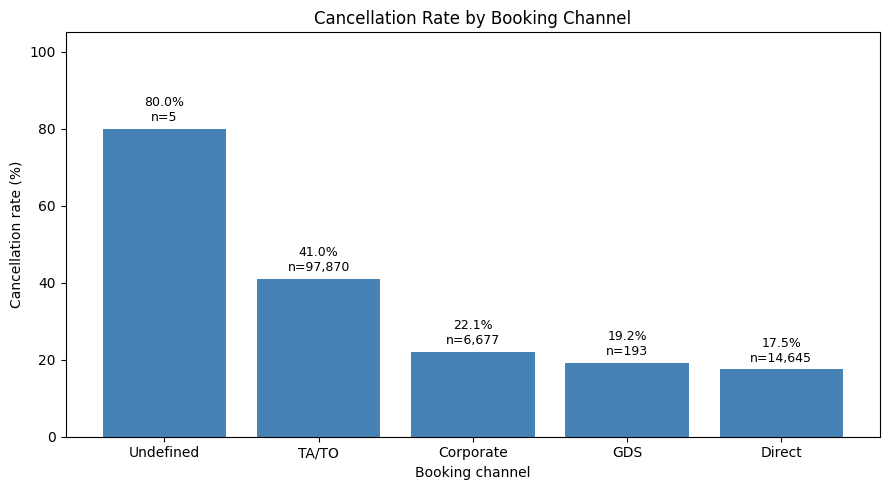

In [17]:
channel_summary = (
    clean_df.groupby("distribution_channel", dropna=False)
    .agg(
        total_bookings=("is_canceled", "size"),
        cancelled_bookings=("is_canceled", "sum"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

channel_summary["cancellation_rate"] *= 100

channel_summary = channel_summary.sort_values(
    "cancellation_rate", ascending=False
)

display(channel_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    channel_summary["distribution_channel"],
    channel_summary["cancellation_rate"],
    color="steelblue"
)

ax.set_title("Cancellation Rate by Booking Channel")
ax.set_xlabel("Booking channel")
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, 105)

for i, row in enumerate(channel_summary.itertuples()):
    ax.text(
        i, row.cancellation_rate + 2,
        f"{row.cancellation_rate:.1f}%\nn={row.total_bookings:,}",
        ha="center", fontsize=9
    )

plt.tight_layout()
plt.savefig("cancellation_by_channel.png", dpi=200)
plt.show()

,lead_time_group,total_bookings,cancellation_rate
0,0–7,19746,9.63
1,8–30,18960,27.86
2,31–90,29553,37.70
3,91–180,26439,44.71
4,181+,24692,57.01


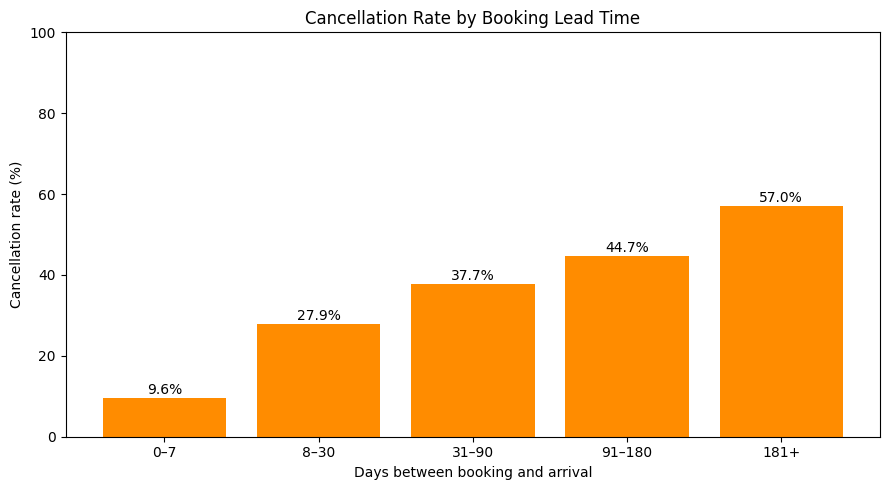

In [18]:
lead_summary = (
    clean_df.groupby("lead_time_group", observed=True)
    .agg(
        total_bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

lead_summary["cancellation_rate"] *= 100

display(lead_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    lead_summary["lead_time_group"].astype(str),
    lead_summary["cancellation_rate"],
    color="darkorange"
)

ax.set_title("Cancellation Rate by Booking Lead Time")
ax.set_xlabel("Days between booking and arrival")
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, 100)

for i, rate in enumerate(lead_summary["cancellation_rate"]):
    ax.text(i, rate + 1, f"{rate:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("lead_time_cancellation.png", dpi=200)
plt.show()

,repeat_guest_label,total_bookings,cancelled_bookings,cancellation_rate
0,First-time guest,115580,43672,37.79
1,Repeat guest,3810,552,14.49


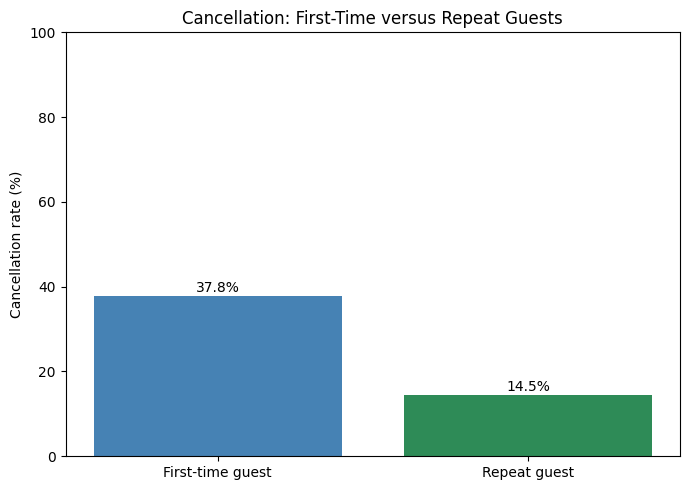

In [20]:
repeat_summary = (
    clean_df.groupby("repeat_guest_label")
    .agg(
        total_bookings=("is_canceled", "size"),
        cancelled_bookings=("is_canceled", "sum"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

repeat_summary["cancellation_rate"] *= 100

display(repeat_summary.round(2))

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    repeat_summary["repeat_guest_label"],
    repeat_summary["cancellation_rate"],
    color=["steelblue", "seagreen"]
)

ax.set_title("Cancellation: First-Time versus Repeat Guests")
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, 100)

for i, rate in enumerate(repeat_summary["cancellation_rate"]):
    ax.text(i, rate + 1, f"{rate:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("repeat_guest_cancellation.png", dpi=200)
plt.show()

In [22]:
channel_summary.to_csv("channel_summary.csv", index=False)
lead_summary.to_csv("lead_time_summary.csv", index=False)
repeat_summary.to_csv("repeat_guest_summary.csv", index=False)

,season,total_bookings,completed_stays,cancellation_rate,completed_stay_nights
0,Winter,9999,6707,32.92,18900
1,Spring,15730,10277,34.67,32460
2,Summer,14927,9507,36.31,35872
3,Autumn,16051,9879,38.45,32566


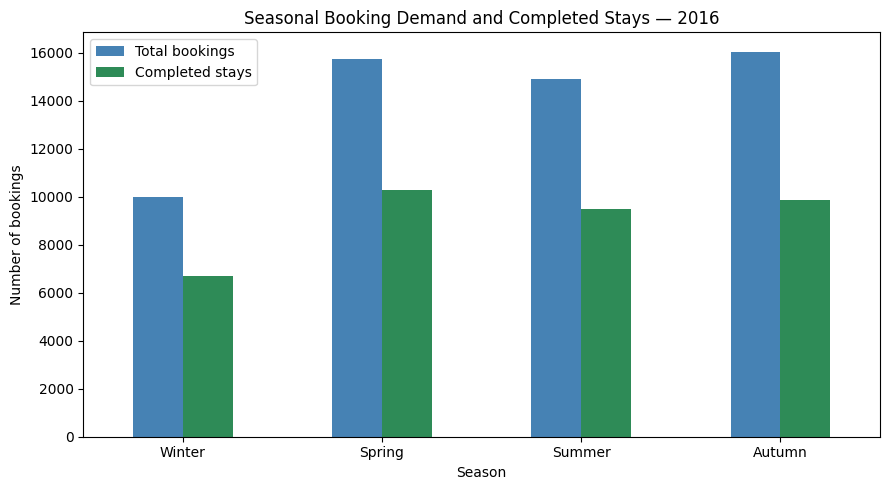

In [23]:
year_df = clean_df[
    clean_df["arrival_date"].dt.year.eq(2016)
].copy()

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_summary = (
    year_df.groupby("season")
    .agg(
        total_bookings=("is_canceled", "size"),
        completed_stays=("completed_stay", "sum"),
        cancellation_rate=("is_canceled", "mean"),
        completed_stay_nights=("completed_stay_nights", "sum")
    )
    .reindex(season_order)
    .reset_index()
)

season_summary["cancellation_rate"] *= 100

display(season_summary.round(2))

season_summary.set_index("season")[
    ["total_bookings", "completed_stays"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "seagreen"]
)

plt.title("Seasonal Booking Demand and Completed Stays — 2016")
plt.xlabel("Season")
plt.ylabel("Number of bookings")
plt.xticks(rotation=0)
plt.legend(["Total bookings", "Completed stays"])
plt.tight_layout()
plt.savefig("seasonal_demand.png", dpi=200)
plt.show()

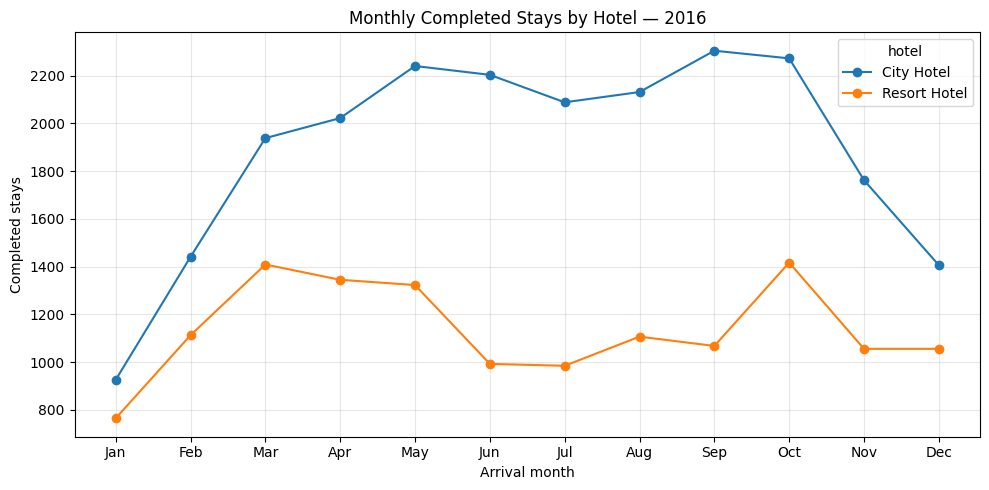

In [24]:
monthly_summary = (
    year_df.groupby(["arrival_month_number", "hotel"])
    .agg(
        total_bookings=("is_canceled", "size"),
        completed_stays=("completed_stay", "sum")
    )
    .reset_index()
)

monthly_pivot = monthly_summary.pivot(
    index="arrival_month_number",
    columns="hotel",
    values="completed_stays"
).reindex(range(1, 13), fill_value=0)

monthly_pivot.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Monthly Completed Stays by Hotel — 2016")
plt.xlabel("Arrival month")
plt.ylabel("Completed stays")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("monthly_hotel_demand.png", dpi=200)
plt.show()

,customer_type,total_bookings,cancelled_bookings,cancellation_rate,average_lead_time
2,Transient,89613,36514,40.75,93.30
0,Contract,4076,1262,30.96,142.97
3,Transient-Party,25124,6389,25.43,137.04
1,Group,577,59,10.23,55.06


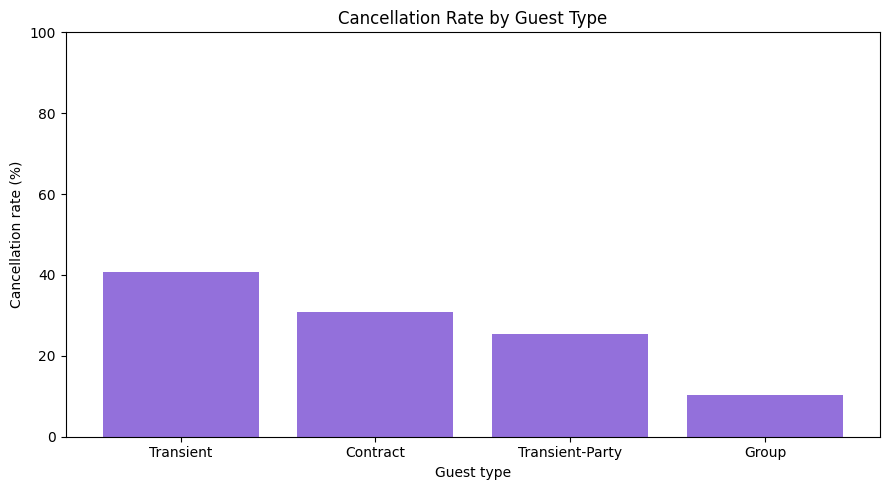

In [25]:
guest_summary = (
    clean_df.groupby("customer_type", dropna=False)
    .agg(
        total_bookings=("is_canceled", "size"),
        cancelled_bookings=("is_canceled", "sum"),
        cancellation_rate=("is_canceled", "mean"),
        average_lead_time=("lead_time", "mean")
    )
    .reset_index()
    .sort_values("cancellation_rate", ascending=False)
)

guest_summary["cancellation_rate"] *= 100

display(guest_summary.round(2))

plt.figure(figsize=(9, 5))
plt.bar(
    guest_summary["customer_type"],
    guest_summary["cancellation_rate"],
    color="mediumpurple"
)
plt.title("Cancellation Rate by Guest Type")
plt.xlabel("Guest type")
plt.ylabel("Cancellation rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("guest_type_cancellation.png", dpi=200)
plt.show()

,hotel,reserved_room_type,total_bookings,completed_stays,cancellation_rate,median_daily_rate,average_stay_length
0,City Hotel,A,62595,35347,43.53,93.78,2.85
1,City Hotel,B,1115,747,33.00,87.00,3.40
2,City Hotel,C,14,9,35.71,89.50,2.14
3,City Hotel,D,11768,7621,35.24,131.78,3.49
4,City Hotel,E,1553,1048,32.52,161.70,3.45
5,City Hotel,F,1791,1091,39.08,189.17,3.28
6,City Hotel,G,484,365,24.59,221.74,3.39
7,City Hotel,P,10,0,100.00,0.00,1.50
8,Resort Hotel,A,23399,17017,27.27,60.58,3.86
9,Resort Hotel,B,3,3,0.00,110.00,1.33


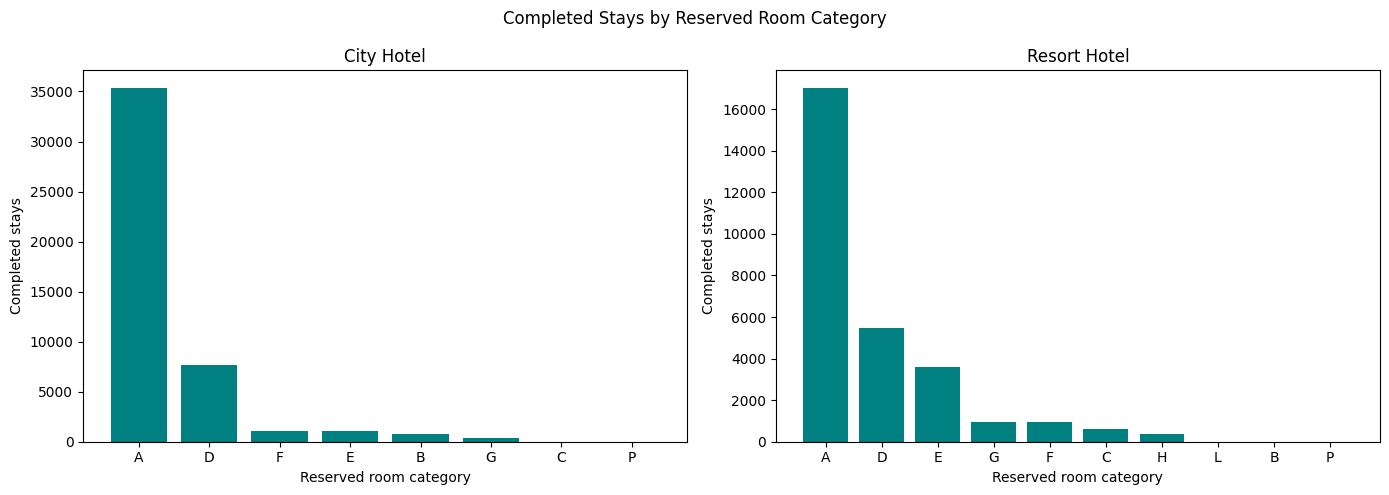

In [26]:
room_summary = (
    clean_df.groupby(["hotel", "reserved_room_type"])
    .agg(
        total_bookings=("is_canceled", "size"),
        completed_stays=("completed_stay", "sum"),
        cancellation_rate=("is_canceled", "mean"),
        median_daily_rate=("adr_clean", "median"),
        average_stay_length=("total_nights", "mean")
    )
    .reset_index()
)

room_summary["cancellation_rate"] *= 100

display(room_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, hotel_name in zip(
    axes, sorted(clean_df["hotel"].unique())
):
    subset = room_summary[
        room_summary["hotel"].eq(hotel_name)
    ].sort_values("completed_stays", ascending=False)

    ax.bar(
        subset["reserved_room_type"],
        subset["completed_stays"],
        color="teal"
    )
    ax.set_title(hotel_name)
    ax.set_xlabel("Reserved room category")
    ax.set_ylabel("Completed stays")

plt.suptitle("Completed Stays by Reserved Room Category")
plt.tight_layout()
plt.savefig("room_performance.png", dpi=200)
plt.show()

In [27]:
season_summary.to_csv("season_summary.csv", index=False)
monthly_summary.to_csv("monthly_summary.csv", index=False)
guest_summary.to_csv("guest_type_summary.csv", index=False)
room_summary.to_csv("room_performance_summary.csv", index=False)

print("Four analysis tables saved.")

Four analysis tables saved.


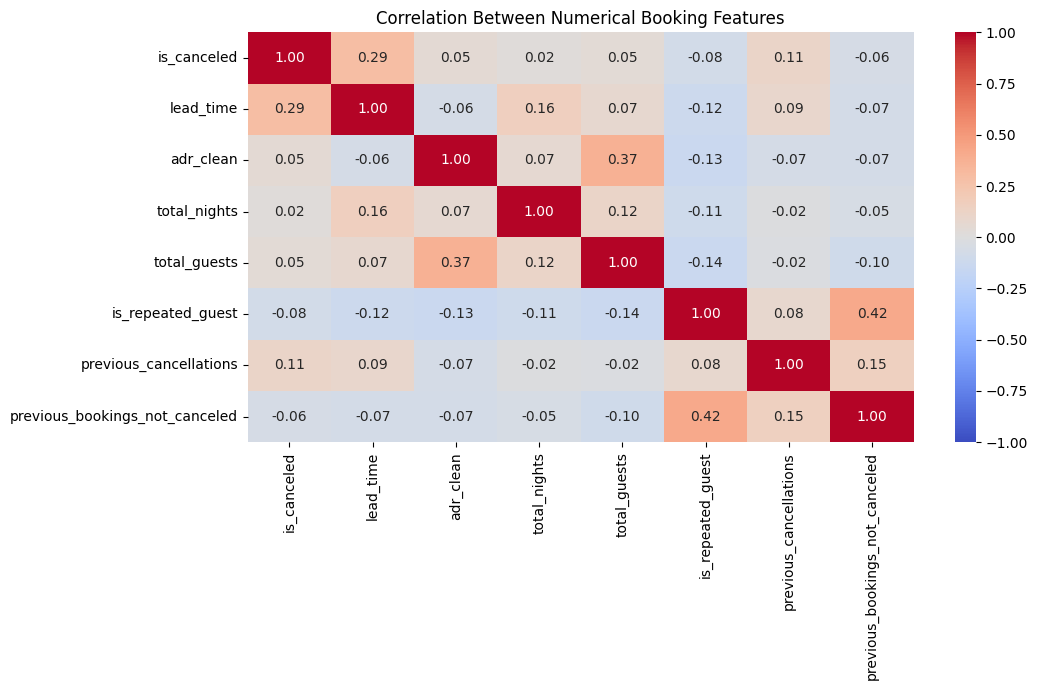

In [28]:
numeric_features = [
    "is_canceled",
    "lead_time",
    "adr_clean",
    "total_nights",
    "total_guests",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

correlation = clean_df[numeric_features].corr()

plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Booking Features")
plt.tight_layout()
plt.savefig("booking_correlation.png", dpi=200)
plt.show()

In [29]:
selected_features = [
    "hotel",
    "distribution_channel",
    "customer_type",
    "reserved_room_type",
    "deposit_type",
    "season",
    "lead_time",
    "adr_clean",
    "total_nights",
    "total_guests",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

X = clean_df[selected_features].copy()
y = clean_df["is_canceled"].copy()

print("Selected input features:", X.shape[1])
display(X.head())

Selected input features: 13


,hotel,distribution_channel,customer_type,reserved_room_type,deposit_type,season,lead_time,adr_clean,total_nights,total_guests,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled
0,Resort Hotel,Direct,Transient,C,No Deposit,Summer,342,0.0,0,2.0,0,0,0
1,Resort Hotel,Direct,Transient,C,No Deposit,Summer,737,0.0,0,2.0,0,0,0
2,Resort Hotel,Direct,Transient,A,No Deposit,Summer,7,75.0,1,1.0,0,0,0
3,Resort Hotel,Corporate,Transient,A,No Deposit,Summer,13,75.0,1,1.0,0,0,0
4,Resort Hotel,TA/TO,Transient,A,No Deposit,Summer,14,98.0,2,2.0,0,0,0


In [30]:
categorical_features = [
    "hotel",
    "distribution_channel",
    "customer_type",
    "reserved_room_type",
    "deposit_type",
    "season"
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=False,
    dtype=int
)

print("Before encoding:", X.shape)
print("After encoding:", X_encoded.shape)

display(X_encoded.head())

Before encoding: (119390, 13)
After encoding: (119390, 35)


,lead_time,adr_clean,total_nights,total_guests,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,hotel_City Hotel,hotel_Resort Hotel,distribution_channel_Corporate,...,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,season_Autumn,season_Spring,season_Summer,season_Winter
0,342,0.0,0,2.0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
1,737,0.0,0,2.0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,7,75.0,1,1.0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
3,13,75.0,1,1.0,0,0,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
4,14,98.0,2,2.0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0


In [31]:
feature_list = pd.DataFrame({
    "selected_feature": selected_features
})

feature_list.to_csv("selected_features.csv", index=False)

encoded_dataset = X_encoded.copy()
encoded_dataset["is_canceled"] = y

encoded_dataset.to_csv(
    "encoded_booking_features.csv",
    index=False
)

print("Feature list and encoded dataset saved.")

Feature list and encoded dataset saved.


Features were selected using their relevance to booking cancellation. Categorical variables were one-hot encoded, and outcome-related fields were excluded to prevent data leakage. PCA was not applied because the selected features remain manageable and interpretable for business analysis. No predictive model is required for this EDA assessment.